# Assignment 7: A Monotone, Convex IFR Interpolator
**Aditya Amit Shah | as22008**  
FRE-GY 9743 - Special Topics: Models to Markets

This project implements a custom, continuous piecewise-quadratic interpolator through the supplied instantaneous forward-rate (IFR) points. It proves the shape conditions, integrates the curve analytically, plots SOFR and Fed Funds, and compares all three supplied products against the piecewise-constant (PCP) baseline.

**Scope:** the original quotes, product terms, valuation date and `FLAT` extrapolation are unchanged. Only the interpolation-method setting differs within each pricing pair. The one-node funding spread stays constant at 0.0005. No calibration is performed. The optional gradient methods remain unimplemented, as requested.

Run all cells from the repository root. Dependencies and validation commands are in `README.md`.


## 1. Method and shape guarantees

Let the supplied point data be $(t_i,y_i)$, with $t_{i+1}>t_i$, and define
$$h_i=t_{i+1}-t_i,\qquad s_i=\frac{y_{i+1}-y_i}{h_i}.$$
An exact **globally monotone and convex** interpolant on $[t_0,t_n]$ is possible only if:

1. All $s_i\geq0$ (increasing), or all $s_i\leq0$ (decreasing).
2. $s_{i+1}\geq s_i$ (nondecreasing secant slopes, the discrete convexity condition).

These conditions are also sufficient: the polygonal interpolant would already satisfy them. I use bounded quadratic curvature to provide curvature between nodes while retaining a simple proof and an exact integral. Convex here means mathematically convex, including affine intervals; it does not mean concave or merely visually smooth.

For at least three nodes, let $g_i=s_{i+1}-s_i\geq0$ and choose
$$c_i=\min\left(|s_i|,\ \tfrac12\min_{j\in\{i-1,i\}\text{ valid}}g_j\right).$$
At the first and last intervals, only the available adjacent gap is used. For two nodes, set $c_0=0$. On interval $i$, with $d=t-t_i\in[0,h_i]$, define
$$\boxed{f(t)=y_i+(s_i-c_i)d+\frac{c_i}{h_i}d^2.}$$

**Exact points and continuity.** At $d=0$ the value is $y_i$; at $d=h_i$ it is $y_i+s_ih_i=y_{i+1}$. Adjacent intervals meet exactly.

**Monotonicity.** The derivative ranges from $s_i-c_i$ to $s_i+c_i$. Since $0\leq c_i\leq|s_i|$, both endpoints are nonnegative for increasing data or nonpositive for decreasing data. Consequently there is no overshoot beyond either interval's endpoint values. Positive input IFRs remain positive, but negative IFR inputs are allowed and are not clipped.

**Convexity, including knots.** Inside each interval, $f''(t)=2c_i/h_i\geq0$. Across a knot,
$$f'(t_{i+1}^-)=s_i+c_i\leq s_{i+1}-c_{i+1}=f'(t_{i+1}^+),$$
because $c_i+c_{i+1}\leq g_i$. The derivative therefore never decreases, including its jumps, which proves convexity over the entire node interval. The curve is **$C^0$, not necessarily $C^1$**. This is an intentional tradeoff: the assignment requires continuity, not continuous derivatives.

**Incompatible data.** Nonmonotone ordinates or decreasing secants cannot be fitted exactly by a globally monotone convex function. The implementation issues a `RuntimeWarning`, sets `shape_compatible=False`, records `fallback_reason`, and uses exact piecewise-linear interpolation. It preserves the quotes and interval-wise monotonicity without falsely claiming the impossible global shape. No input is silently recalibrated. Empty, nonfinite, repeated, or unsorted nodes are rejected.

**Extrapolation and the funding curve.** Outside the node interval, $f(t)=y_0$ on the left and $f(t)=y_n$ on the right. Flat tails preserve monotonicity, but generally break global convexity at one boundary: the shape guarantee is explicitly restricted to $[t_0,t_n]$. A single node defines a constant function everywhere.


## 2. Exact integration and valuation

An interval primitive from its left node is
$$A_i(d)=y_i d+\frac{s_i-c_i}{2}d^2+\frac{c_i}{3h_i}d^3.$$
Thus the complete interval area is
$$A_i(h_i)=\frac{h_i(y_i+y_{i+1})}{2}-\frac{c_i h_i^2}{6}.$$
The implementation caches cumulative interval areas and adds a partial polynomial area or a flat-tail rectangle. For arbitrary finite limits,
$$\int_a^b f(t)\,dt=F(b)-F(a).$$
This handles reversed limits, zero-length intervals, knot crossings and both extrapolation tails. Construction costs $O(n)$ and each scalar interpolation or integral query costs $O(\log n)$.

The course's IFR relations give
$$P_j(0,T)=\exp\left[-\int_0^{t(T)} f_j(u)\,du\right],\qquad
L_j(A,B)=\frac{P_j(0,A)/P_j(0,B)-1}{\tau(A,B)}.$$
The model uses **Actual/Actual ISDA** for curve time and the supplied **ACT/360** coupon conventions. I use the library's `accrued` function for plotting and diagnostic times, so they match the model exactly. The funding identifier references SOFR and adds the constant spread:
$$D(0,T)=P_{\mathrm{SOFR}}(0,T)e^{-0.0005t(T)}.$$
Consequently changing the SOFR interpolation affects both projected payments and discount factors; it does not just change the floating rate.

**Relation to Hagan-West.** Hagan and West (2006), *Interpolation Methods for Curve Construction*, Section “Forward Monotone Convex Spline,” equations (30)-(35), start from **interval-average discrete forwards** and preserve their interval integrals. Here the starter explicitly supplies **IFR point values**. Applying those averages directly to this input would solve a different problem. This project borrows the idea of local shape constraints and piecewise polynomials, but implements the point-interpolating rule above, not the published Hagan-West algorithm. The reference PDF is included in the repository as `Hagan_West_curves_AMF.pdf`.

The discount-factor and forward-rate identities also follow the course note *A Note on Simple Curve Construction*, Section 1.1, equation (1), Jianing (Jay) Yao, September 23, 2026.


## 3. Supplied market data

The following data cell is retained from the instructor starter.

In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from fixedincomelib import qfCreate1DInterpolator
from fixedincomelib.date import Date, accrued

output_dir = Path("submission")
output_dir.mkdir(exist_ok=True)
value_date = Date("2026-01-02")
node_times = np.array([accrued(value_date, Date(d)) for d in node_dates])
curves = {}
secant_rows = []
for name, quotes in [("SOFR", sofr_quotes), ("Fed Funds", ff_quotes)]:
    y = quotes["values"].to_numpy()
    curves[name] = {
        method: qfCreate1DInterpolator(node_times, y, method, "FLAT")
        for method in ["PIECEWISE_CONSTANT_LEFT_CONTINUOUS", "MONOTONE_CONVEX"]
    }
    curve = curves[name]["MONOTONE_CONVEX"]
    assert curve.shape_compatible
    for i, (s, c) in enumerate(zip(curve.slopes_, curve.curvatures_)):
        secant_rows.append({"Curve": name, "Start": node_dates[i], "End": node_dates[i+1],
                            "Secant (bp/year)": 10000*s,
                            "Curvature c (bp/year)": 10000*c,
                            "Left derivative (bp/year)": 10000*(s-c),
                            "Right derivative (bp/year)": 10000*(s+c)})
secant_table = pd.DataFrame(secant_rows)
display(secant_table.round(6))
secant_table.to_csv(output_dir / "curve_shape_diagnostics.csv", index=False)


,Curve,Start,End,Secant (bp/year),Curvature c (bp/year),Left derivative (bp/year),Right derivative (bp/year)
0,SOFR,2026-04-02,2026-10-02,19.945355,3.397286,16.548069,23.342641
1,SOFR,2026-10-02,2027-07-02,26.739927,3.397286,23.342641,30.137213
2,SOFR,2027-07-02,2028-01-03,39.460625,5.337992,34.122633,44.798618
3,SOFR,2028-01-03,2029-01-02,50.136610,4.931695,45.204915,55.068305
4,SOFR,2029-01-02,2031-01-02,60.000000,4.931695,55.068305,64.931695
5,Fed Funds,2026-04-02,2026-10-02,13.961749,3.046598,10.915150,17.008347
6,Fed Funds,2026-10-02,2027-07-02,20.054945,2.797231,17.257714,22.852176
7,Fed Funds,2027-07-02,2028-01-03,25.649406,2.797231,22.852176,28.446637
8,Fed Funds,2028-01-03,2029-01-02,40.109288,4.945356,35.163932,45.054644
9,Fed Funds,2029-01-02,2031-01-02,50.000000,4.945356,45.054644,54.945356


Both supplied curves have positive, strictly increasing secant slopes, so neither needs the fallback. The table shows the actual endpoint derivatives used in the proof. The single funding-spread node is handled as an everywhere-constant function.

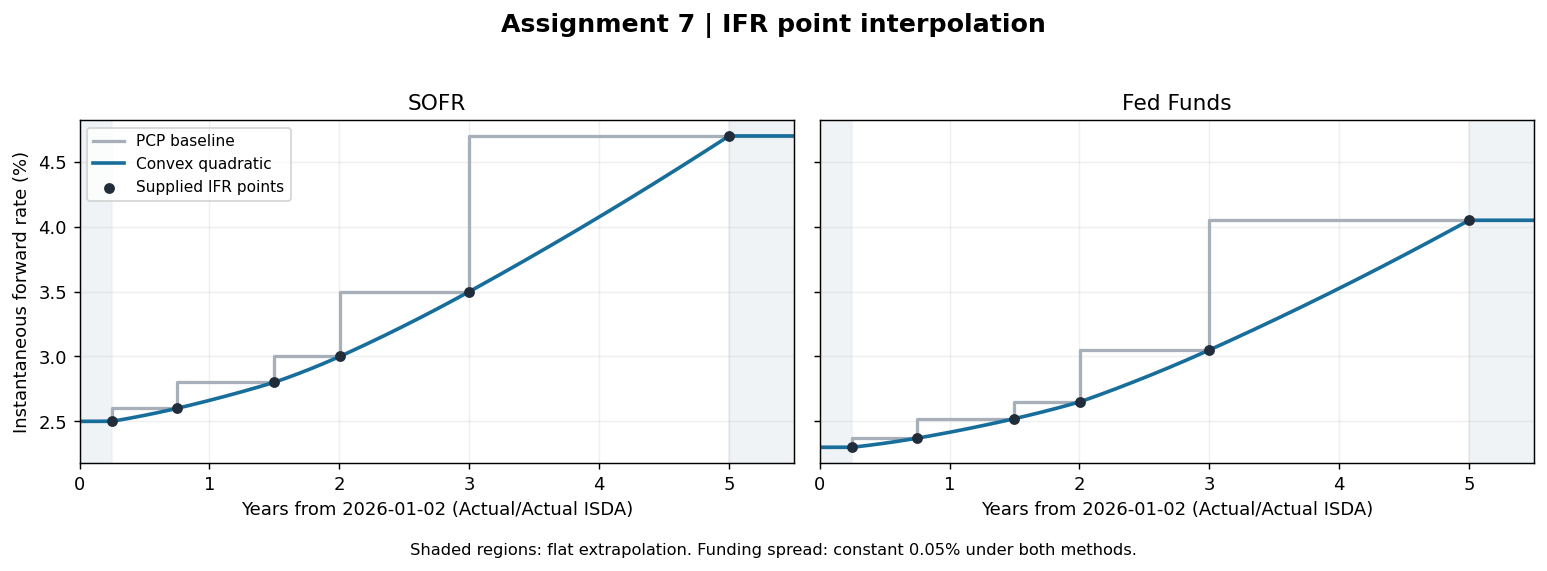

In [3]:
plt.rcParams.update({"figure.dpi": 130, "font.size": 10})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
grid = np.unique(np.r_[np.linspace(0, 5.5, 1400), node_times])
for ax, (name, quotes) in zip(axes, [("SOFR", sofr_quotes), ("Fed Funds", ff_quotes)]):
    y = quotes["values"].to_numpy()
    # PCP uses the right node's value on (t_i, t_{i+1}]; draw that convention explicitly.
    ax.step(np.r_[0, node_times, 5.5], 100*np.r_[y[0], y, y[-1]],
            where="pre", label="PCP baseline", color="#a7afb9", linewidth=1.8)
    curve = curves[name]["MONOTONE_CONVEX"]
    ax.plot(grid, [100*curve.interpolate(t) for t in grid],
            label="Convex quadratic", color="#176e9b", linewidth=2)
    ax.scatter(node_times, 100*y, color="#222d3b", s=25, zorder=3, label="Supplied IFR points")
    ax.axvspan(0, node_times[0], color="#e9edf1", alpha=0.65)
    ax.axvspan(node_times[-1], 5.5, color="#e9edf1", alpha=0.65)
    ax.set(title=name, xlabel="Years from 2026-01-02 (Actual/Actual ISDA)", xlim=(0, 5.5))
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Instantaneous forward rate (%)")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Assignment 7 | IFR point interpolation", fontsize=14, weight="bold")
fig.text(0.5, 0.01, "Shaded regions: flat extrapolation. Funding spread: constant 0.05% under both methods.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
fig.savefig(output_dir / "ifr_curves.png", dpi=180, bbox_inches="tight")
plt.show()


The quadratic lies below the straight chord because its curvature is nonnegative. On increasing data it also lies below the PCP right-endpoint rectangle. Its IFR integrals are therefore smaller than PCP's over the same interval. Discount factors are correspondingly larger, and projected compounded floating returns smaller. Matching IFR nodes does **not** match node discount factors: those depend on all intervening areas, and the assignment requires no recalibration.

## 4. Original pricing comparisons

All six pricing cells below retain the instructor’s explicit inputs and API calls. “Receive” means receive fixed for the FRA and RFR swap, and receive SOFR plus the 10 bp spread for the basis swap.

In [4]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [5]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3263.971121798475
Student minus PCP: 355.68448256051124


In [6]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513069528


In [7]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12836.477674195368
Student minus PCP: 6613.96016112584


In [8]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [9]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7622.813582911644
Student minus PCP: -728.5353252703499


## 5. Results and explanation

In [10]:
comparison = pd.DataFrame({
    "Product": ["FRA (receive fixed)", "RFR swap (receive fixed)", "Basis swap (receive SOFR + spread)"],
    "PCP PV (USD)": [fra_pcp_pv, swap_pcp_pv, basis_pcp_pv],
    "Quadratic PV (USD)": [fra_student_pv, swap_student_pv, basis_student_pv],
})
comparison["Change (USD)"] = comparison["Quadratic PV (USD)"] - comparison["PCP PV (USD)"]
display(comparison.round(6))
comparison.to_csv(output_dir / "pv_comparison.csv", index=False)
for prefix in ["fra", "swap", "basis"]:
    pcp = globals()[prefix + "_pcp_convention"]
    student = globals()[prefix + "_student_convention"]
    assert set(pcp) == set(student)
    assert [k for k in pcp if pcp[k] != student[k]] == ["interpolation method"]
print("Verified: only the interpolation-method setting differs within each pair.")


,Product,PCP PV (USD),Quadratic PV (USD),Change (USD)
0,FRA (receive fixed),2908.286639,3263.971122,355.684483
1,RFR swap (receive fixed),6222.517513,12836.477674,6613.960161
2,Basis swap (receive SOFR + spread),8351.348908,7622.813583,-728.535325


Verified: only the interpolation-method setting differs within each pair.


**FRA:** PV rises from **\$2,908.286639** to **\$3,263.971122**, a **\$355.684483** increase. For this library's end-paid receive-fixed FRA,
$$V=N\tau\,(K-L_{\mathrm{SOFR}}(A,B))D(0,B).$$
The lower integrated SOFR reduces the projected floating rate. The fixed-minus-floating payoff is positive here, so the larger discount factor also increases its PV.

**RFR swap:** PV rises from **\$6,222.517513** to **\$12,836.477674**, a **\$6,613.960161** increase. Each receive-fixed coupon contributes
$$N\left[K\tau_k-\left(\frac{P_{\mathrm{SOFR}}(0,A_k)}{P_{\mathrm{SOFR}}(0,B_k)}-1\right)\right]D(0,T_k),$$
with the actual payment date $T_k$ including the supplied two-business-day lag. Lower projected SOFR improves the receive-fixed position over three years. Discounting also changes; its contribution depends on each signed coupon, so the total result is calculated rather than inferred from a single rate.

**Basis swap:** PV falls from **\$8,351.348908** to **\$7,622.813583**, a **\$728.535325** decrease. It receives SOFR plus 10 bp and pays Fed Funds. Both index legs decline, but the reduction in the received SOFR leg exceeds the reduction in the paid Fed Funds leg. The next table shows those contributions explicitly. The larger funding discount factors slightly increase the positive spread-leg PV. There is no general rule that interpolation must raise or lower a basis-swap PV: both projection curves and funding matter.

These numbers measure the effect of the specified curve representation at unchanged IFR quotes. They are not evidence that one method is more accurate against market prices; the exercise supplies no calibration instruments or observed prices for such a claim.


In [11]:
from fixedincomelib import qfCreateCashflowsReport

cashflow_frames = []
for product_name, prefix in [("FRA", "fra"), ("RFR swap", "swap"), ("Basis swap", "basis")]:
    for method in ["pcp", "student"]:
        frame = qfCreateCashflowsReport(
            globals()[f"{prefix}_{method}_model"], globals()[f"{prefix}_{method}_product"],
            globals()[f"{prefix}_{method}_parameters"],
        ).display()
        assert np.isclose(frame["PV"].sum(), globals()[f"{prefix}_{method}_pv"], atol=1e-7, rtol=0)
        frame.insert(0, "Method", "PCP" if method == "pcp" else "Quadratic")
        frame.insert(0, "Product", product_name)
        cashflow_frames.append(frame)
cashflows = pd.concat(cashflow_frames, ignore_index=True)
cashflows.to_csv(output_dir / "cashflows.csv", index=False)
leg_comparison = cashflows.groupby(["Product", "Leg", "Method"])["PV"].sum().unstack("Method")
leg_comparison["Change (USD)"] = leg_comparison["Quadratic"] - leg_comparison["PCP"]
display(leg_comparison.round(6))
print("All six cashflow reports reconcile to the reported product PVs.")


Method                            PCP     Quadratic  Change (USD)
Product    Leg                                                   
Basis swap Leg 1 index   57542.733563  54496.262672  -3046.470891
           Leg 1 spread   1942.659611   1945.597985      2.938374
           Leg 2 index  -51134.044266 -48819.047074   2314.997192
FRA        Fixed         15996.002733  16003.058041      7.055308
           Floating     -13087.716094 -12739.086919    348.629175
RFR swap   Fixed         96775.084971  97112.390723    337.305752
           Floating     -90552.567458 -84275.913049   6276.654409

All six cashflow reports reconcile to the reported product PVs.


## 6. Validation and limitations

The automated suite checks exact interpolation, known quadratic functions, continuity, monotonicity, convexity through Jensen inequalities, no overshoot, irregular spacing, negative rates, flat tails, constant and two-node cases, incompatible inputs, and invalid data. Integrals are checked against independent Gauss-Legendre quadrature, including reversed limits and node crossings. Randomized shape checks use a fixed seed for reproducibility.

The pricing tests execute the six original pricing cells and independently rebuild the discounted cashflows using numerical quadrature of the IFR functions, without calling the interpolator's integral or the model's discount-factor method. They also check the constant funding spread and that each pair changes only interpolation. The notebook retains the plot, slope diagnostics, PV comparisons, and signed-leg reconciliation.

Limitations: derivative continuity is not guaranteed at knots; shape guarantees do not extend to the flat extrapolation tails; incompatible input data use a disclosed linear fallback; and the optional ordinate-gradient methods are intentionally left as stubs. There is no calibration, smoothing fit, or claim of exact Hagan-West implementation.

## 7. Submission

Submit the completed notebook **together with the library**, or the repository branch link if Brightspace accepts links. `submission/Assignment_7_as22008.html` is the readable copy with saved outputs. The full code archive is useful if file upload is required. A notebook alone will not run without `fixedincomelib` and `static_files`.

The posted deadline is **November 12, 2026**. The provided announcement does not specify a time or a required upload format; follow the fields and deadline shown in Brightspace. Publishing to GitHub does not submit the assignment to Brightspace.
